# Online Retail II: Business Analysis
**Goal:** Answer key business questions about revenue, products, countries, and customers.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean files we saved in the cleaning notebook
df = pd.read_csv("../data/processed/clean_data.csv", parse_dates=["InvoiceDate"])
df_customers = pd.read_csv("../data/processed/clean_customers.csv", parse_dates=["InvoiceDate"])
cancellations = pd.read_csv("../data/processed/cancellations.csv")

print("Rows loaded:", len(df))

Rows loaded: 1001809


Question 1: What are our headline numbers?

In [17]:
total_revenue = df["Revenue"].sum()
total_orders = df["Invoice"].nunique()      # nunique = number of unique values
total_customers = df_customers["Customer ID"].nunique()
avg_order_value = total_revenue / total_orders

print("Total revenue:", round(total_revenue, 2))
print("Total orders:", total_orders)
print("Total customers:", total_customers)
print("Average order value:", round(avg_order_value, 2))

Total revenue: 19238548.91
Total orders: 39374
Total customers: 5850
Average order value: 488.61


In [18]:
cancelled_orders = cancellations["Invoice"].nunique()
cancel_rate = cancelled_orders / (total_orders + cancelled_orders) * 100

print("Cancelled orders:", cancelled_orders)
print("Cancellation rate:", round(cancel_rate, 2), "%")

Cancelled orders: 8292
Cancellation rate: 17.4 %


In [19]:
# Count how many different orders each customer made
orders_per_customer = df_customers.groupby("Customer ID")["Invoice"].nunique()

# A repeat customer has more than 1 order
repeat_rate = (orders_per_customer > 1).mean() * 100

print("Repeat purchase rate:", round(repeat_rate, 2), "%")

Repeat purchase rate: 72.29 %


Question 2: How does revenue change over time?

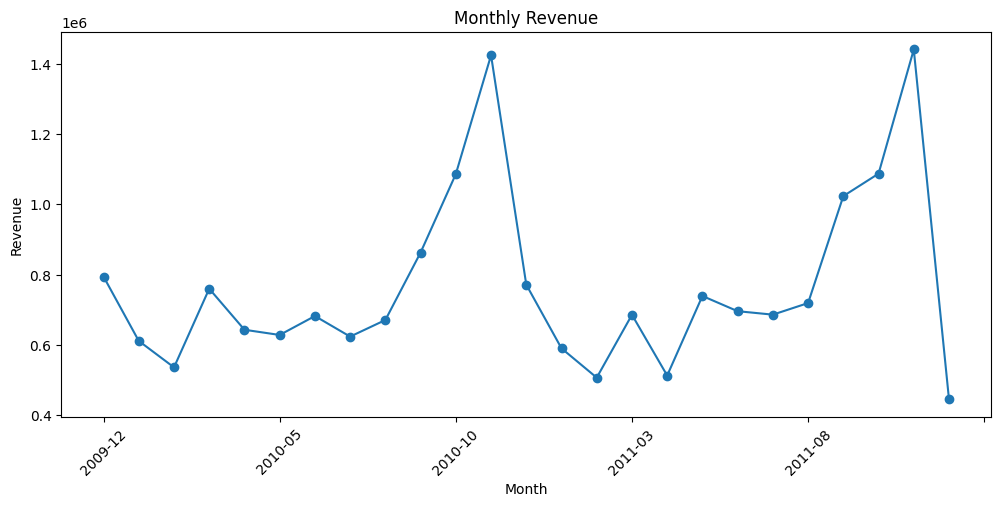

In [20]:
# Group by month and add up the revenue
monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()

monthly_revenue.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

Question 3: Which products and countries earn the most?

In [21]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
top_products

Description
REGENCY CAKESTAND 3 TIER               328434.22
WHITE HANGING HEART T-LIGHT HOLDER     258619.02
PARTY BUNTING                          148270.58
JUMBO BAG RED RETROSPOT                146567.54
ASSORTED COLOUR BIRD ORNAMENT          128989.40
PAPER CHAIN KIT 50'S CHRISTMAS         116818.69
CHILLI LIGHTS                           80002.93
ROTATING SILVER ANGELS T-LIGHT HLDR     71300.40
JUMBO BAG STRAWBERRY                    68593.83
RABBIT NIGHT LIGHT                      66857.55
Name: Revenue, dtype: float64

In [22]:
top_countries = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
top_countries

Country
United Kingdom    16409000.97
EIRE                614228.72
Netherlands         549773.41
Germany             383169.10
France              309853.49
Australia           167423.41
Spain                97766.75
Switzerland          93629.44
Sweden               86081.14
Denmark              67422.69
Name: Revenue, dtype: float64

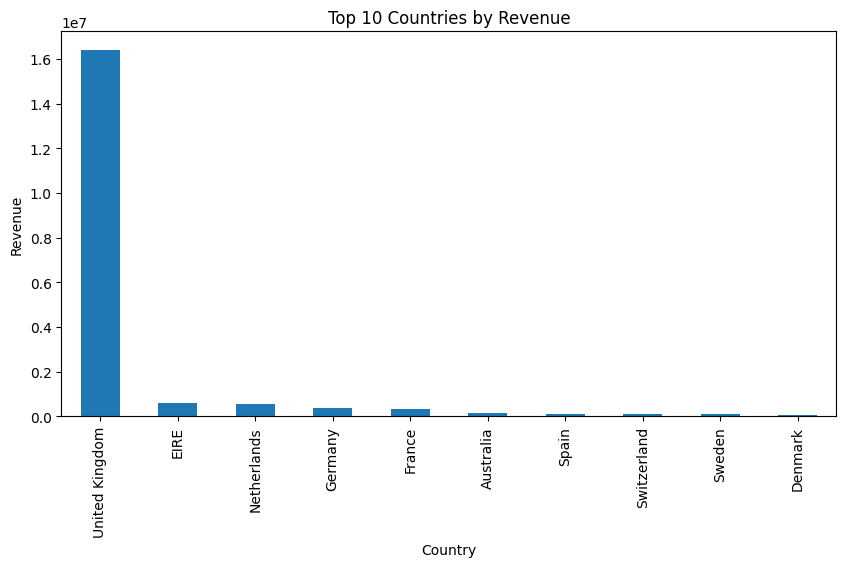

In [23]:
top_countries.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Countries by Revenue")
plt.ylabel("Revenue")
plt.show()

In [24]:
   df[df["Description"] == "PAPER CRAFT , LITTLE BIRDIE"][["Invoice", "Quantity", "Price", "InvoiceDate"]]

,Invoice,Quantity,Price,InvoiceDate


## Customer Segmentation: RFM Analysis

In [25]:
# We need a "today" date to measure recency from.
# Use the day after the last order in the data.
snapshot_date = df_customers["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

# One row per customer with their last purchase date, number of orders, and total spend
rfm = df_customers.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
).reset_index()

# Recency = days between their last purchase and the snapshot date
rfm["Recency"] = (snapshot_date - rfm["LastPurchase"]).dt.days

rfm.head()

Snapshot date: 2011-12-10 12:50:00


,Customer ID,LastPurchase,Frequency,Monetary,Recency
0,12346,2010-06-28 13:53:00,2,169.36,529
1,12347,2011-12-07 15:52:00,8,4921.53,2
2,12348,2011-09-25 13:13:00,5,1658.40,75
3,12349,2011-11-21 09:51:00,3,3678.69,19
4,12350,2011-02-02 16:01:00,1,294.40,310


In [26]:
# qcut splits customers into 5 equal-sized groups.
# For Recency, FEWER days is better, so the labels run 5 down to 1.
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# For Frequency and Monetary, MORE is better.
# We rank first because many customers have exactly 1 order, and qcut can't split identical values.
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm.head()

,Customer ID,LastPurchase,Frequency,Monetary,Recency,R,F,M
0,12346,2010-06-28 13:53:00,2,169.36,529,1,2,1
1,12347,2011-12-07 15:52:00,8,4921.53,2,5,4,5
2,12348,2011-09-25 13:13:00,5,1658.40,75,3,4,4
3,12349,2011-11-21 09:51:00,3,3678.69,19,5,3,5
4,12350,2011-02-02 16:01:00,1,294.40,310,2,1,2


In [27]:
def assign_segment(row):
    if row["R"] >= 4 and row["F"] >= 4:
        return "Champions"          # bought recently, buy often
    elif row["R"] >= 3 and row["F"] >= 3:
        return "Loyal Customers"    # fairly recent, fairly frequent
    elif row["R"] >= 3:
        return "New / Promising"    # bought recently, but not often yet
    elif row["F"] >= 3:
        return "At Risk"            # used to buy often, haven't been back
    else:
        return "Lost"               # haven't bought in a long time, and rarely did

# Apply the function to every row (axis=1 means "row by row")
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

rfm["Segment"].value_counts()

Segment
Lost               1508
Champions          1474
Loyal Customers    1208
New / Promising     832
At Risk             828
Name: count, dtype: int64

In [28]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    TotalRevenue=("Monetary", "sum"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgSpend=("Monetary", "mean"),
).round(1)

# What share of customers and revenue does each segment hold?
segment_summary["PctCustomers"] = (segment_summary["Customers"] / segment_summary["Customers"].sum() * 100).round(1)
segment_summary["PctRevenue"] = (segment_summary["TotalRevenue"] / segment_summary["TotalRevenue"].sum() * 100).round(1)

segment_summary.sort_values("TotalRevenue", ascending=False)

,Customers,TotalRevenue,AvgRecency,AvgFrequency,AvgSpend,PctCustomers,PctRevenue
Segment,,,,,,,
Champions,1474,11723144.8,20.4,15.5,7953.3,25.2,70.3
Loyal Customers,1208,2380667.8,78.2,5.3,1970.8,20.6,14.3
At Risk,828,1488221.7,368.3,4.9,1797.4,14.2,8.9
Lost,1508,623561.6,456.5,1.2,413.5,25.8,3.7
New / Promising,832,448828.9,64.2,1.4,539.5,14.2,2.7


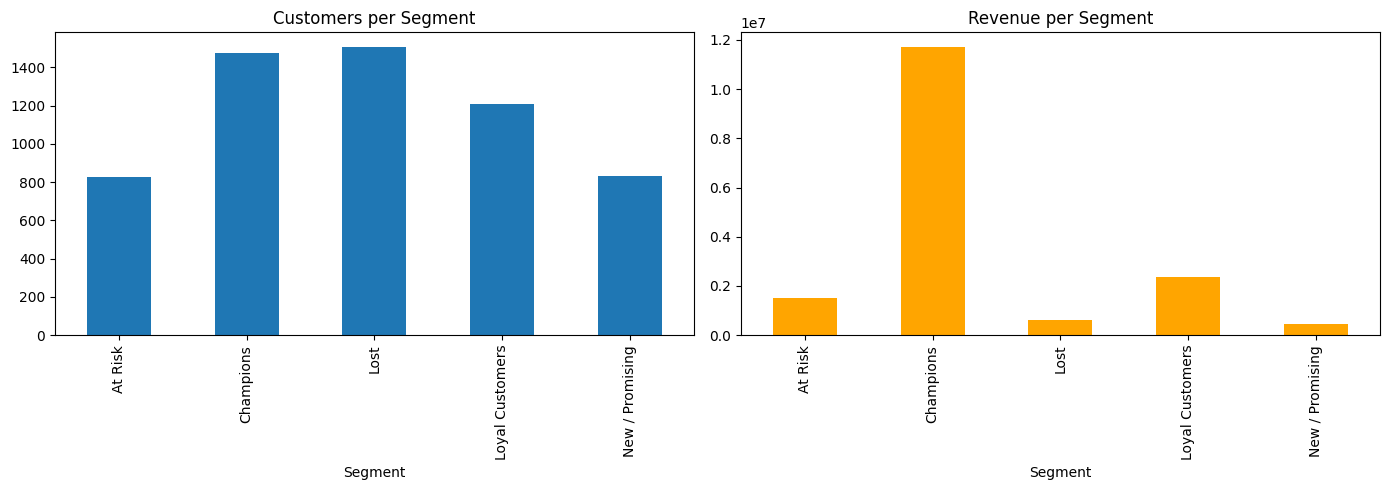

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

segment_summary["Customers"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Customers per Segment")

segment_summary["TotalRevenue"].plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Revenue per Segment")

plt.tight_layout()
plt.show()

In [30]:
rfm.to_csv("../data/processed/rfm_customers.csv", index=False)
segment_summary.to_csv("../data/processed/rfm_segment_summary.csv")
print("Saved!")

Saved!


## Cohort Retention Analysis
**Cohort** = the group of customers whose first purchase was in the same month.

In [31]:
import seaborn as sns

# Work on a copy so df_customers stays unchanged
cohort_df = df_customers.copy()

# The month of each order, like 2010-03
cohort_df["OrderMonth"] = cohort_df["InvoiceDate"].dt.to_period("M")

# The month of each customer's FIRST order = their cohort
cohort_df["CohortMonth"] = cohort_df.groupby("Customer ID")["OrderMonth"].transform("min")

cohort_df[["Customer ID", "OrderMonth", "CohortMonth"]].head()

,Customer ID,OrderMonth,CohortMonth
0,13085,2009-12,2009-12
1,13085,2009-12,2009-12
2,13085,2009-12,2009-12
3,13085,2009-12,2009-12
4,13085,2009-12,2009-12


In [32]:
# 0 = their first month, 1 = the month after, 2 = two months after, and so on
year_diff = cohort_df["OrderMonth"].dt.year - cohort_df["CohortMonth"].dt.year
month_diff = cohort_df["OrderMonth"].dt.month - cohort_df["CohortMonth"].dt.month

cohort_df["MonthsSinceFirst"] = year_diff * 12 + month_diff

cohort_df[["Customer ID", "CohortMonth", "OrderMonth", "MonthsSinceFirst"]].head()

,Customer ID,CohortMonth,OrderMonth,MonthsSinceFirst
0,13085,2009-12,2009-12,0
1,13085,2009-12,2009-12,0
2,13085,2009-12,2009-12,0
3,13085,2009-12,2009-12,0
4,13085,2009-12,2009-12,0


In [33]:
# For each cohort and month number, count how many different customers ordered
cohort_data = cohort_df.groupby(["CohortMonth", "MonthsSinceFirst"])["Customer ID"].nunique().reset_index()
cohort_data = cohort_data.rename(columns={"Customer ID": "Customers"})

# Turn the months into text so they plot and save cleanly
cohort_data["CohortMonth"] = cohort_data["CohortMonth"].astype(str)

# Reshape: one row per cohort, one column per month number
cohort_counts = cohort_data.pivot(index="CohortMonth", columns="MonthsSinceFirst", values="Customers")

cohort_counts.iloc[:, :6]

MonthsSinceFirst,0,1,2,3,4,5
CohortMonth,,,,,,
2009-12,951.0,332.0,317.0,404.0,360.0,342.0
2010-01,368.0,78.0,117.0,116.0,99.0,114.0
2010-02,374.0,88.0,85.0,110.0,92.0,73.0
2010-03,441.0,84.0,102.0,107.0,102.0,90.0
2010-04,293.0,56.0,56.0,47.0,54.0,65.0
2010-05,253.0,39.0,43.0,45.0,45.0,65.0
2010-06,267.0,47.0,50.0,55.0,62.0,76.0
2010-07,186.0,29.0,34.0,55.0,54.0,26.0
2010-08,163.0,32.0,47.0,53.0,27.0,19.0


In [34]:
# Column 0 is the cohort size (everyone buys in their first month)
cohort_size = cohort_counts[0]

# Divide every column by the cohort size and multiply by 100
retention = cohort_counts.divide(cohort_size, axis=0) * 100

retention.round(1).iloc[:, :6]

MonthsSinceFirst,0,1,2,3,4,5
CohortMonth,,,,,,
2009-12,100.0,34.9,33.3,42.5,37.9,36.0
2010-01,100.0,21.2,31.8,31.5,26.9,31.0
2010-02,100.0,23.5,22.7,29.4,24.6,19.5
2010-03,100.0,19.0,23.1,24.3,23.1,20.4
2010-04,100.0,19.1,19.1,16.0,18.4,22.2
2010-05,100.0,15.4,17.0,17.8,17.8,25.7
2010-06,100.0,17.6,18.7,20.6,23.2,28.5
2010-07,100.0,15.6,18.3,29.6,29.0,14.0
2010-08,100.0,19.6,28.8,32.5,16.6,11.7


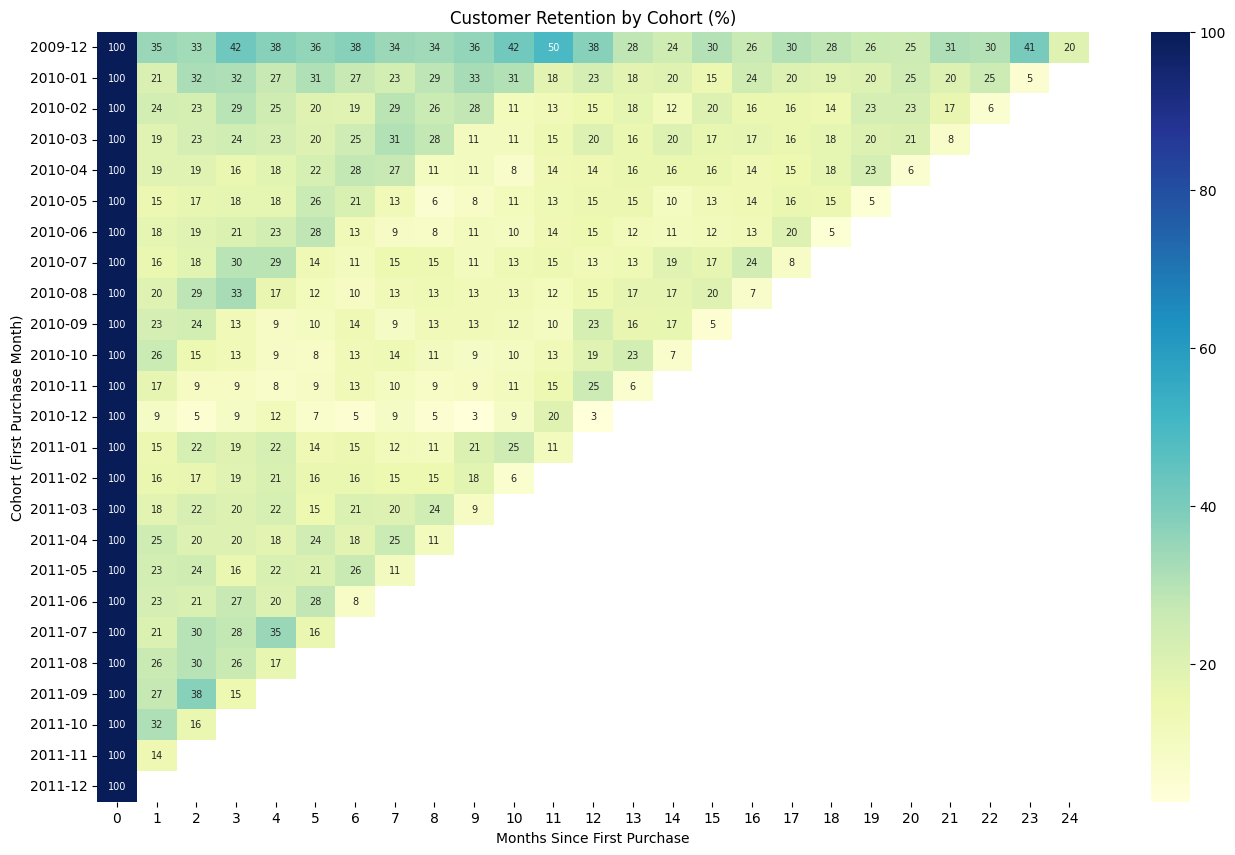

In [35]:
plt.figure(figsize=(16, 10))
sns.heatmap(retention, annot=True, fmt=".0f", cmap="YlGnBu", annot_kws={"size": 7})
plt.title("Customer Retention by Cohort (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cohort (First Purchase Month)")
plt.show()

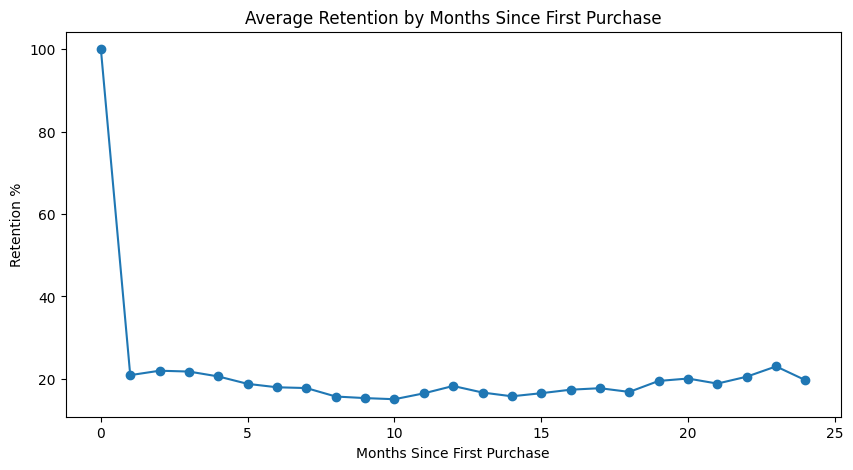

MonthsSinceFirst
0     100.0
1      20.9
2      22.0
3      21.8
4      20.6
5      18.8
6      17.9
7      17.8
8      15.7
9      15.3
10     15.0
11     16.5
12     18.3
dtype: float64

In [36]:
# Average each column across all cohorts (empty cells are skipped automatically)
avg_retention = retention.mean()

avg_retention.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Average Retention by Months Since First Purchase")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Retention %")
plt.show()

avg_retention.round(1).head(13)

In [37]:
# Long format (one row per cohort and month) is easiest for Power BI
retention_long = retention.reset_index().melt(
    id_vars="CohortMonth", var_name="MonthsSinceFirst", value_name="RetentionPct"
).dropna()

retention_long.to_csv("../data/processed/cohort_retention.csv", index=False)
print("Saved!")

Saved!
